# A/B Test & Retention Analysis – Cookie Cats

A mobile puzzle game moved its first **gate** (where players must wait or pay to continue) from **level 30 to level 40**.
Players were randomly assigned to one of the two versions. Did the change affect how many players come back?

## 1. Hypothesis (written before looking at the data)

| | |
|---|---|
| **Null hypothesis (H0)** | Moving the gate to level 40 does **not** change 7-day retention. |
| **Alternative (H1)** | Moving the gate to level 40 **does** change 7-day retention. |
| **Main metric** | 7-day retention (`retention_7`) |
| **Second metric** | 1-day retention (`retention_1`) |
| **Significance level** | α = 0.05 |
| **Control / Test** | `gate_30` (old) / `gate_40` (new) |

## 2. Load and check the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)          # makes the bootstrap reproducible
COLORS = {"gate_30": "#1f4e79", "gate_40": "#c0504d"}

df = pd.read_csv("../data/cookie_cats.csv")
print(df.shape)
print(df.head())
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate users:", df["userid"].duplicated().sum())
print("\n", df["version"].value_counts())

(90189, 5)
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True

Missing values:
 userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Duplicate users: 0

 version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


### Sample ratio check
Both groups should be about the same size. A chi-square goodness-of-fit test against a 50/50 split checks this.

In [2]:
counts = df["version"].value_counts()
print(counts)
print(f"gate_30 share: {counts['gate_30'] / counts.sum():.2%}")
chi2_srm, p_srm = stats.chisquare(counts.values)
print(f"Sample ratio test p-value: {p_srm:.4f}")

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
gate_30 share: 49.56%
Sample ratio test p-value: 0.0086


## 3. Game rounds and outliers

count    90189.0
mean        51.9
std        195.1
min          0.0
25%          5.0
50%         16.0
75%         51.0
max      49854.0
Name: sum_gamerounds, dtype: float64


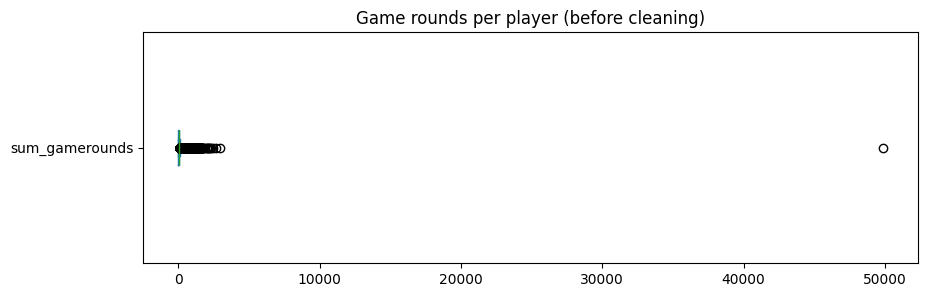

        userid  version  sum_gamerounds  retention_1  retention_7
57702  6390605  gate_30           49854        False         True
7912    871500  gate_30            2961         True         True
29417  3271615  gate_40            2640         True        False
43671  4832608  gate_30            2438         True         True
48188  5346171  gate_40            2294         True         True

Players with 0 rounds: 3994 (4.4%)


In [3]:
print(df["sum_gamerounds"].describe().round(1))

plt.figure(figsize=(10, 3))
df["sum_gamerounds"].plot(kind="box", vert=False)
plt.title("Game rounds per player (before cleaning)")
plt.savefig("../dashboard/rounds_box.png", dpi=150, bbox_inches="tight")
plt.show()

print(df.sort_values("sum_gamerounds", ascending=False).head())
print("\nPlayers with 0 rounds:", (df["sum_gamerounds"] == 0).sum(),
      f"({(df['sum_gamerounds'] == 0).mean():.1%})")

One player has **49,854 rounds** in 14 days while the next highest is about 3,000. That is ~3,500 rounds a day,
which is not realistic for a person – it is almost certainly a data error or a bot, so it is removed.

Players with 0 rounds installed the game but never played. They are **kept**: they are a real part of
both groups (randomisation happened at install), and removing them would change the experiment population.

Removed 1 row. Players left: 90,188
version
gate_40    45489
gate_30    44699
Name: count, dtype: int64
          mean  median
version               
gate_30  51.34    17.0
gate_40  51.30    16.0


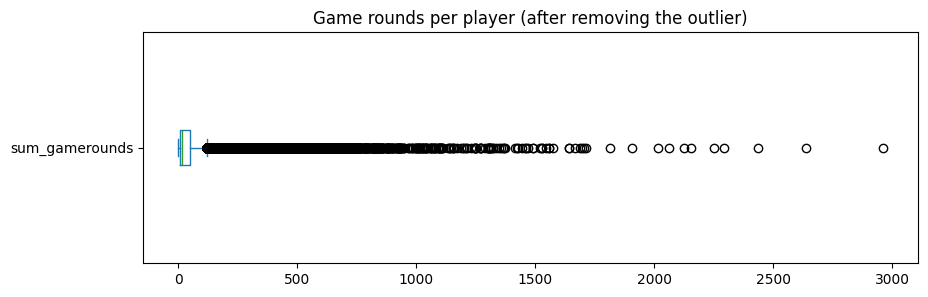

In [4]:
before = len(df)
df = df[df["sum_gamerounds"] < df["sum_gamerounds"].max()]
print(f"Removed {before - len(df)} row. Players left: {len(df):,}")
print(df["version"].value_counts())

print(df.groupby("version")["sum_gamerounds"].agg(["mean", "median"]).round(2))

plt.figure(figsize=(10, 3))
df["sum_gamerounds"].plot(kind="box", vert=False)
plt.title("Game rounds per player (after removing the outlier)")
plt.show()

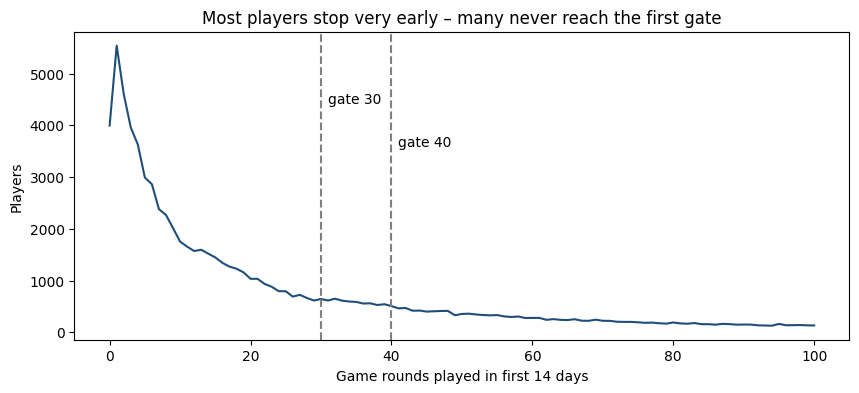

Players who played fewer than 30 rounds: 63.1%


In [5]:
# How many players reach each level of play? (shows why the gate position matters)
reach = df.groupby("sum_gamerounds")["userid"].count()
plt.figure(figsize=(10, 4))
reach.loc[:100].plot(color="#1f4e79")
plt.axvline(30, color="grey", ls="--"); plt.axvline(40, color="grey", ls="--")
plt.text(31, reach.max() * 0.8, "gate 30"); plt.text(41, reach.max() * 0.65, "gate 40")
plt.xlabel("Game rounds played in first 14 days"); plt.ylabel("Players")
plt.title("Most players stop very early – many never reach the first gate")
plt.savefig("../dashboard/rounds_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Players who played fewer than 30 rounds: {(df.sum_gamerounds < 30).mean():.1%}")

## 4. Compare retention

         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20

Difference gate_30 - gate_40 (percentage points):
retention_1    0.59
retention_7    0.82
dtype: float64


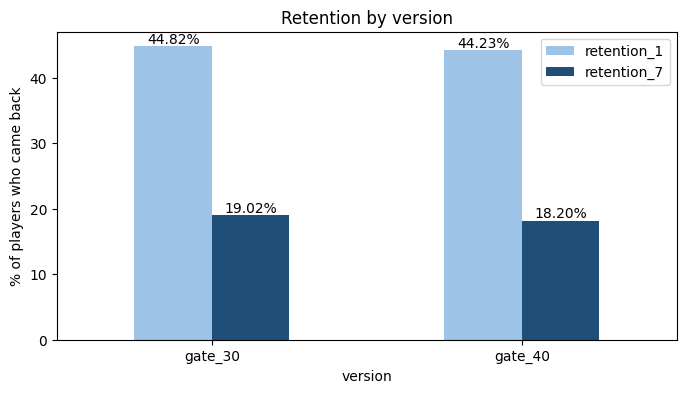

In [6]:
summary = df.groupby("version")[["retention_1", "retention_7"]].mean() * 100
print(summary.round(2))

diff_pp = summary.loc["gate_30"] - summary.loc["gate_40"]
print("\nDifference gate_30 - gate_40 (percentage points):")
print(diff_pp.round(2))

ax = summary.plot(kind="bar", figsize=(8, 4), rot=0, color=["#9dc3e6", "#1f4e79"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f%%")
plt.ylabel("% of players who came back")
plt.title("Retention by version")
plt.savefig("../dashboard/retention_bar.png", dpi=150, bbox_inches="tight")
plt.show()

The difference is small. Is it real, or just luck? The next two steps answer that.

## 5. Bootstrap resampling

Bootstrapping = pretend to re-run the experiment 1,000 times by sampling players **with replacement**.
It shows how much the result could change by chance alone.

In [7]:
def bootstrap(col, n=1000):
    results = []
    for _ in range(n):
        sample = df.sample(frac=1, replace=True)
        results.append(sample.groupby("version")[col].mean())
    return pd.DataFrame(results)

boot7 = bootstrap("retention_7")
boot1 = bootstrap("retention_1")

In [8]:
def report(boot, label):
    diff = (boot["gate_30"] - boot["gate_40"]) / boot["gate_40"] * 100
    lo, hi = np.percentile(diff, [2.5, 97.5])
    print(f"{label}")
    print(f"  Average % difference (gate_30 vs gate_40): {diff.mean():.2f}%")
    print(f"  95% interval: [{lo:.2f}%, {hi:.2f}%]")
    print(f"  Probability gate_30 is better: {(diff > 0).mean():.1%}\n")
    return diff

diff7 = report(boot7, "7-day retention")
diff1 = report(boot1, "1-day retention")

7-day retention
  Average % difference (gate_30 vs gate_40): 4.52%
  95% interval: [1.62%, 7.45%]
  Probability gate_30 is better: 100.0%

1-day retention
  Average % difference (gate_30 vs gate_40): 1.32%
  95% interval: [-0.12%, 2.80%]
  Probability gate_30 is better: 96.4%



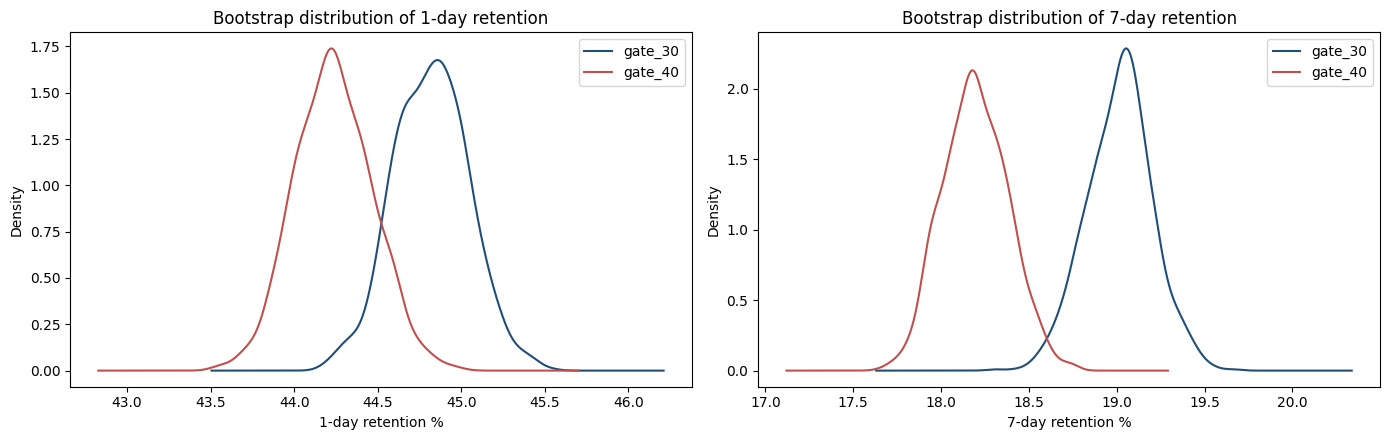

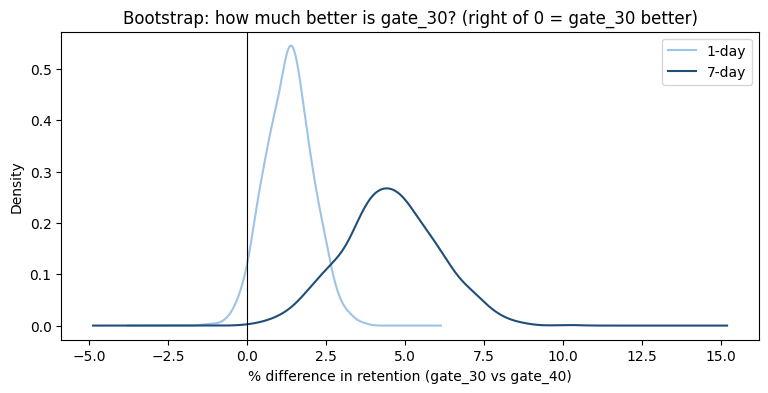

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, boot, title in [(axes[0], boot1, "1-day"), (axes[1], boot7, "7-day")]:
    for v in ["gate_30", "gate_40"]:
        (boot[v] * 100).plot(kind="kde", ax=ax, color=COLORS[v], label=v)
    ax.set_xlabel(f"{title} retention %"); ax.legend()
    ax.set_title(f"Bootstrap distribution of {title} retention")
plt.tight_layout()
plt.savefig("../dashboard/bootstrap_kde.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
diff1.plot(kind="kde", ax=ax, label="1-day", color="#9dc3e6")
diff7.plot(kind="kde", ax=ax, label="7-day", color="#1f4e79")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("% difference in retention (gate_30 vs gate_40)")
ax.set_title("Bootstrap: how much better is gate_30? (right of 0 = gate_30 better)")
ax.legend()
plt.savefig("../dashboard/bootstrap_diff.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read it:** if the 95% interval does not include 0, the difference is very likely real.

## 6. Chi-square test

The chi-square test of independence checks whether "came back or not" depends on the version.

In [10]:
results = {}
for col in ["retention_1", "retention_7"]:
    table = pd.crosstab(df["version"], df[col])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    results[col] = p
    print(col)
    print(table)
    print(f"chi2 = {chi2:.2f}, p-value = {p:.4f}")
    print("Significant" if p < 0.05 else "Not significant", "\n")

retention_1
retention_1  False  True 
version                  
gate_30      24665  20034
gate_40      25370  20119
chi2 = 3.17, p-value = 0.0750
Not significant 

retention_7
retention_7  False  True 
version                  
gate_30      36198   8501
gate_40      37210   8279
chi2 = 9.92, p-value = 0.0016
Significant 



## 7. Extra check: does the gate change how much people play?

Rounds played are very skewed, so a Mann-Whitney U test (compares distributions, not means) is used.

In [11]:
a = df.loc[df.version == "gate_30", "sum_gamerounds"]
b = df.loc[df.version == "gate_40", "sum_gamerounds"]
u, p_mw = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"Median rounds gate_30: {a.median():.0f}, gate_40: {b.median():.0f}")
print(f"Mann-Whitney U p-value: {p_mw:.4f}")

Median rounds gate_30: 17, gate_40: 16
Mann-Whitney U p-value: 0.0509


## Export results for the Power BI dashboard

In [12]:
rows = []
for col, d, label in [("retention_1", diff1, "1-day retention"), ("retention_7", diff7, "7-day retention")]:
    rows.append({
        "metric": label,
        "gate_30_pct": round(summary.loc["gate_30", col], 2),
        "gate_40_pct": round(summary.loc["gate_40", col], 2),
        "diff_pp": round(summary.loc["gate_30", col] - summary.loc["gate_40", col], 2),
        "chi2_p_value": round(results[col], 4),
        "boot_ci_low_pct": round(np.percentile(d, 2.5), 2),
        "boot_ci_high_pct": round(np.percentile(d, 97.5), 2),
        "prob_gate30_better_pct": round(100 * (d > 0).mean(), 1),
        "significant": "Yes" if results[col] < 0.05 else "No",
    })
ab_results = pd.DataFrame(rows)
ab_results.to_csv("../data/ab_results.csv", index=False)

pd.DataFrame({"sample": range(1, len(diff7) + 1),
              "diff_1day_pct": diff1.values.round(3),
              "diff_7day_pct": diff7.values.round(3)}).to_csv("../data/bootstrap_samples.csv", index=False)
ab_results

,metric,gate_30_pct,gate_40_pct,diff_pp,chi2_p_value,boot_ci_low_pct,boot_ci_high_pct,prob_gate30_better_pct,significant
0,1-day retention,44.82,44.23,0.59,0.0750,-0.12,2.80,96.4,No
1,7-day retention,19.02,18.20,0.82,0.0016,1.62,7.45,100.0,Yes


## 8. Recommendation

1. **What was tested:** moving the first gate from level 30 to level 40, on **90,188 players** (44,699 gate_30, 45,489 gate_40) after removing one bot/error player with 49,854 rounds.
2. **Retention:** 1-day retention was 44.82% (gate_30) vs 44.23% (gate_40); 7-day retention was **19.02% vs 18.20%**.
3. **Significance:** the 7-day difference **is significant** – chi-square p = 0.0016, the bootstrap 95% interval for the relative difference is about +1.6% to +7.5% (it does not include 0) and gate_30 was better in 100% of the 1,000 bootstrap samples. The 1-day difference is **not** significant (p = 0.075, interval includes 0, 96% probability).
4. **Recommendation: keep the gate at level 30.** Moving it to level 40 lowers 7-day retention by ~0.8 percentage points (about 4.5% fewer returning players), and long-term retention is what drives revenue for a free-to-play game.
5. **Limitations:** (a) we only measured retention, not in-game purchases or player satisfaction – gate_40 might change revenue per player; (b) the sample ratio check shows a small imbalance (49.6% / 50.4%, p = 0.009), so it is worth confirming that the assignment logic worked correctly before a final decision.

**Why the 1-day result is not significant but the 7-day one is:** after 1 day most players have not reached level 30 yet (63% of players played fewer than 30 rounds in total), so the gate position cannot affect them much. By day 7 more players have hit the gate, and an earlier break (level 30) seems to keep them engaged – players who have a forced pause earlier may enjoy the game longer (hedonic adaptation).